In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import category_encoders as ce

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

e:\anaconda\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


### Student Performance Dataset - Column Descriptions

* **Index**: The row number or identifier for each individual record (ranging from 0 to 19 in the snapshot).
* **Hours Studied**: A numerical column representing the total number of hours a student dedicated to studying.
* **Previous Scores**: A numerical column indicating the student's prior grades or academic scores.
* **Extracurricular Activities**: A categorical column with binary values (`Yes` or `No`) denoting whether the student engages in extracurricular activities.
* **Sleep Hours**: A numerical column showing the number of hours the student sleeps.
* **Sample Question Papers Practiced**: A numerical column tracking how many sample exam or test papers the student has completed (contains missing `NaN` values).
* **Performance Index**: A numerical column representing the overall score or target metric measuring student performance.


In [2]:
df = pd.read_csv(r"D:\NTI Machine\Preprocessing\Student_Performance.csv")

In [3]:
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66
...,...,...,...,...,...,...
9995,1,49,Yes,4,2.0,23
9996,7,64,Yes,8,5.0,58
9997,6,83,Yes,8,5.0,74
9998,9,97,Yes,7,0.0,95


In [4]:
df.duplicated().sum()

132

In [5]:
df = df.drop_duplicates()

In [6]:
df.isnull().sum()

Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          1563
Sleep Hours                            0
Sample Question Papers Practiced    2778
Performance Index                      0
dtype: int64

In [7]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9868 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     9868 non-null   int64  
 1   Previous Scores                   9868 non-null   int64  
 2   Extracurricular Activities        8305 non-null   object 
 3   Sleep Hours                       9868 non-null   int64  
 4   Sample Question Papers Practiced  7090 non-null   float64
 5   Performance Index                 9868 non-null   int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 539.7+ KB


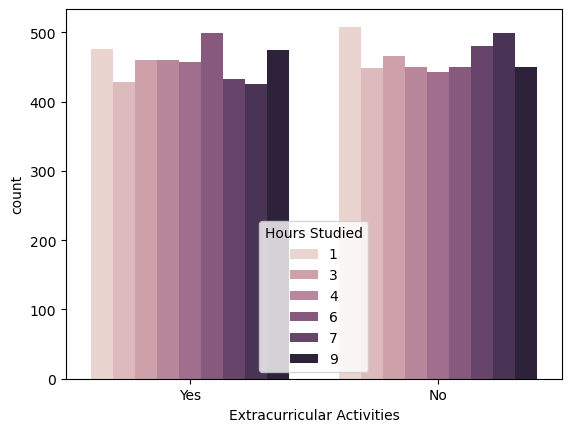

In [9]:
sns.countplot(data = df, x = 'Extracurricular Activities',hue= df['Hours Studied'])
plt.show()

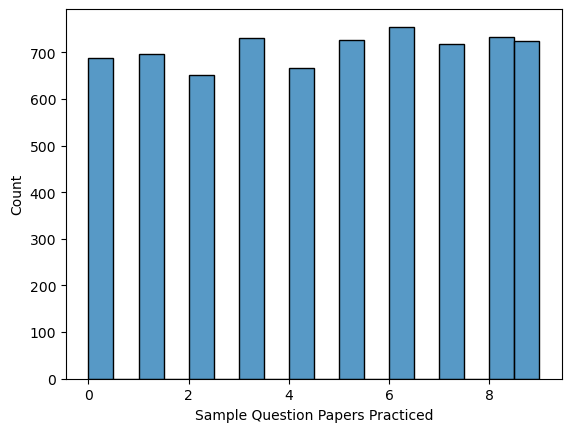

In [10]:
sns.histplot(data = df, x='Sample Question Papers Practiced' )
plt.show()

In [11]:
df['Sample Question Papers Practiced'].fillna(df.groupby(['Previous Scores','Performance Index'])['Sample Question Papers Practiced'].transform('median'),inplace=True)

C:\Users\yawaa\AppData\Local\Temp\ipykernel_3952\2873924650.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sample Question Papers Practiced'].fillna(df.groupby(['Previous Scores','Performance Index'])['Sample Question Papers Practiced'].transform('median'),inplace=True)
C:\Users\yawaa\AppData\Local\Temp\ipykernel_3952\2873924650.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/

<Axes: ylabel='Frequency'>

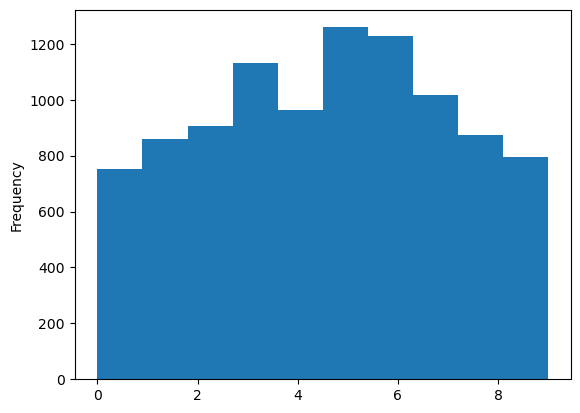

In [12]:
df['Sample Question Papers Practiced'].plot(kind = 'hist')

In [13]:
df[df['Sample Question Papers Practiced'].isnull()].describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,80.000000,80.000000,80.000000,0.0,80.000000
mean,5.750000,71.562500,6.650000,NaN,59.862500
std,3.384626,18.130919,2.038242,NaN,22.486983
min,1.000000,40.000000,4.000000,NaN,11.000000
25%,2.000000,57.000000,4.000000,NaN,43.750000
50%,7.000000,71.500000,7.000000,NaN,57.500000
75%,9.000000,86.500000,9.000000,NaN,76.000000
max,9.000000,99.000000,9.000000,NaN,100.000000


In [14]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,9868.000000,9868.000000,9868.000000,9788.000000,9868.000000
mean,4.992704,69.425922,6.531516,4.571159,55.202675
std,2.589895,17.338295,1.697899,2.659689,19.219320
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.500000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,70.250000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [15]:
df.isnull().sum()

Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          1563
Sleep Hours                            0
Sample Question Papers Practiced      80
Performance Index                      0
dtype: int64

In [16]:
# Safely get the first mode of each group, falling back to a default value like 'No' if empty
df['Extracurricular Activities'] = df['Extracurricular Activities'].fillna(
    df.groupby(['Previous Scores', 'Performance Index'])['Extracurricular Activities']
    .transform(lambda x: x.mode().iloc[0] if not x.mode().empty else 'No')
)

C:\Users\yawaa\AppData\Local\Temp\ipykernel_3952\4121157133.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Extracurricular Activities'] = df['Extracurricular Activities'].fillna(


<Axes: xlabel='Extracurricular Activities', ylabel='count'>

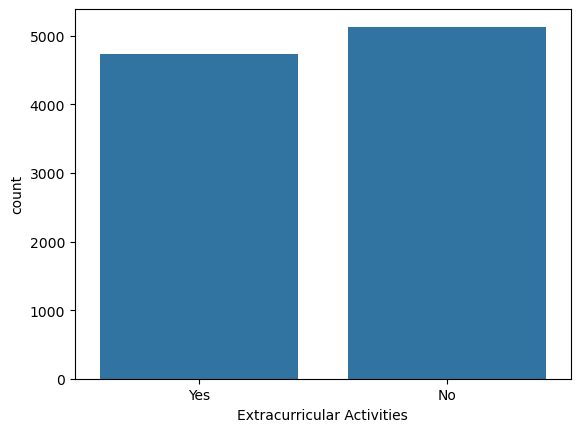

In [17]:
sns.countplot(data = df, x = 'Extracurricular Activities')

In [18]:
df.isnull().sum()

Hours Studied                        0
Previous Scores                      0
Extracurricular Activities           0
Sleep Hours                          0
Sample Question Papers Practiced    80
Performance Index                    0
dtype: int64

In [19]:
df = df.dropna()

In [20]:
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66
...,...,...,...,...,...,...
9995,1,49,Yes,4,2.0,23
9996,7,64,Yes,8,5.0,58
9997,6,83,Yes,8,5.0,74
9998,9,97,Yes,7,0.0,95


In [21]:
mapping = {'Yes':1,'No':0}
df['Extracurricular Activities'] = df['Extracurricular Activities'].map(mapping)

In [22]:
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1.0,91
1,4,82,0,4,2.0,65
2,8,51,1,7,2.0,45
3,5,52,1,5,2.0,36
4,7,75,0,8,5.0,66
...,...,...,...,...,...,...
9995,1,49,1,4,2.0,23
9996,7,64,1,8,5.0,58
9997,6,83,1,8,5.0,74
9998,9,97,1,7,0.0,95


In [23]:
from sklearn.model_selection import train_test_split

In [24]:
y = df['Performance Index']
x = df.drop(columns = 'Performance Index')

In [25]:
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=.2,random_state=10)

In [26]:
from sklearn.linear_model import LinearRegression

In [27]:
model = LinearRegression()

In [28]:
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[2.85,1.02,0.55,0.48,0.17]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Hours Studied','Previous Scores','Extracurricular Activities', 'Sleep Hours','Sample Question Papers Practiced']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-33.91
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5


In [29]:
y_pred = model.predict(X_test)

In [30]:
from sklearn.metrics import mean_squared_error, r2_score

print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

R2 Score: 0.9881123703512109
Mean Squared Error: 4.31211359009323


In [31]:
y_test

7919    95
1916    33
6077    17
1171    35
3142    57
        ..
4524    55
8695    54
5611    52
272     48
4695    59
Name: Performance Index, Length: 1958, dtype: int64

In [32]:
df.corr()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000000,-0.011078,-0.002281,-0.003105,0.031961,0.372809
Previous Scores,-0.011078,1.000000,0.014439,0.006149,-0.002290,0.916106
Extracurricular Activities,-0.002281,0.014439,1.000000,-0.026146,0.002382,0.024747
Sleep Hours,-0.003105,0.006149,-0.026146,1.000000,0.011831,0.046127
Sample Question Papers Practiced,0.031961,-0.002290,0.002382,0.011831,1.000000,0.034263
Performance Index,0.372809,0.916106,0.024747,0.046127,0.034263,1.000000


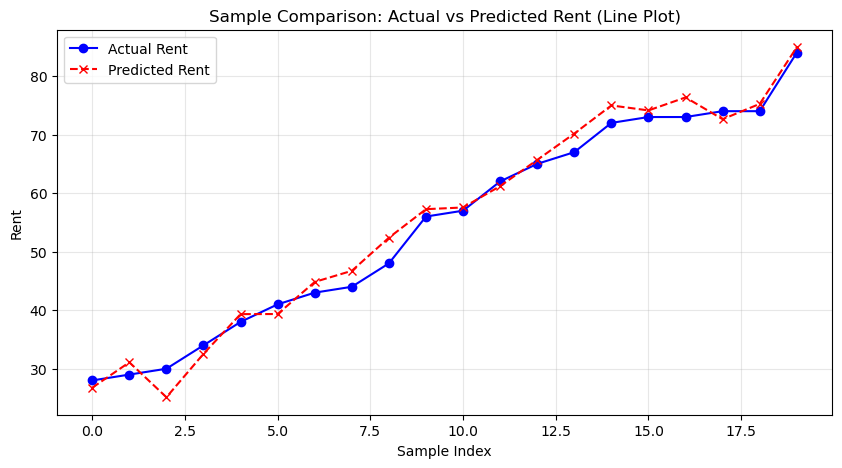

In [33]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Set a random seed for reproducibility
np.random.seed(42)

# 2. Combine into a DataFrame and take a random sample of 20 rows for a cleaner line plot
results_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
}).sample(n=20)

# Optional: Sort by Actual rent so the line plot looks structured rather than tangled
results_df = results_df.sort_values(by='Actual').reset_index(drop=True)

# 3. Plot the sampled actual vs predicted values as lines
plt.figure(figsize=(10, 5))
plt.plot(results_df['Actual'], label='Actual Rent', marker='o', color='blue')
plt.plot(results_df['Predicted'], label='Predicted Rent', marker='x', color='red', linestyle='--')

plt.xlabel("Sample Index")
plt.ylabel("Rent")
plt.title("Sample Comparison: Actual vs Predicted Rent (Line Plot)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [34]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [35]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [36]:
from tqdm import tqdm

  0%|          | 0/15 [00:00<?, ?it/s]

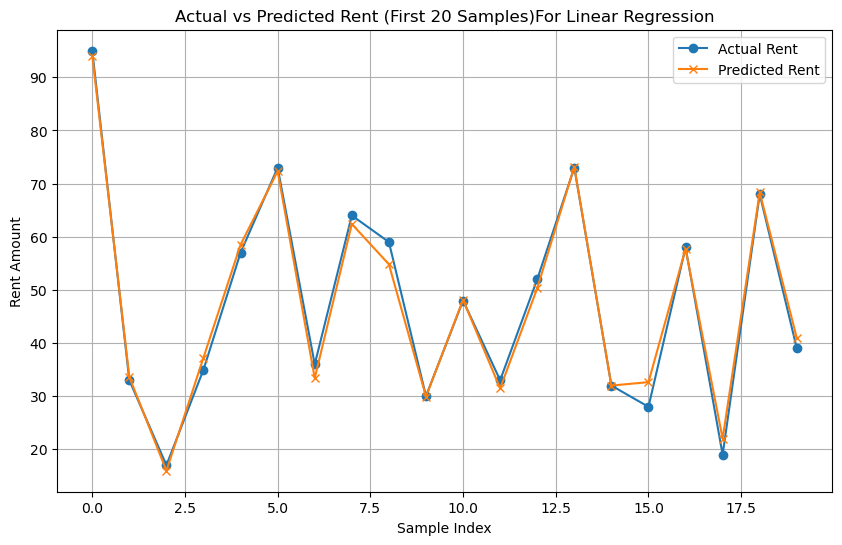

  7%|▋         | 1/15 [00:00<00:05,  2.62it/s]

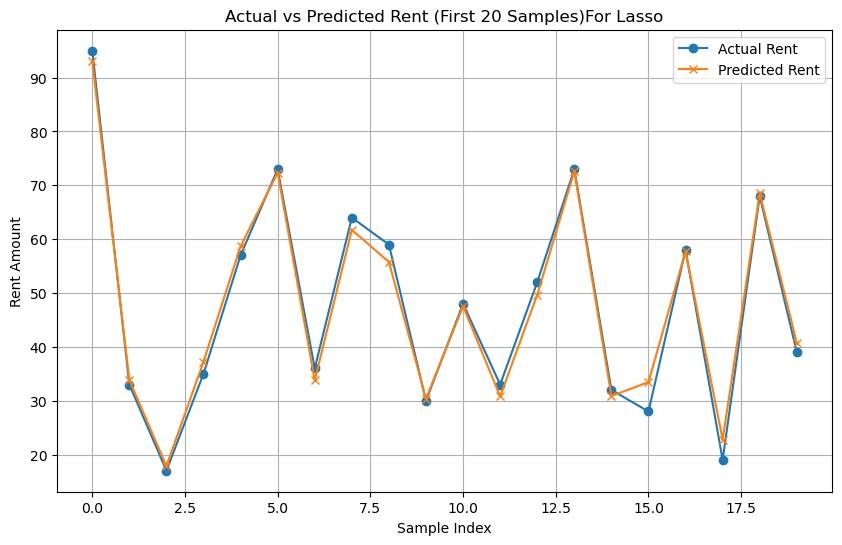

 13%|█▎        | 2/15 [00:00<00:04,  2.68it/s]

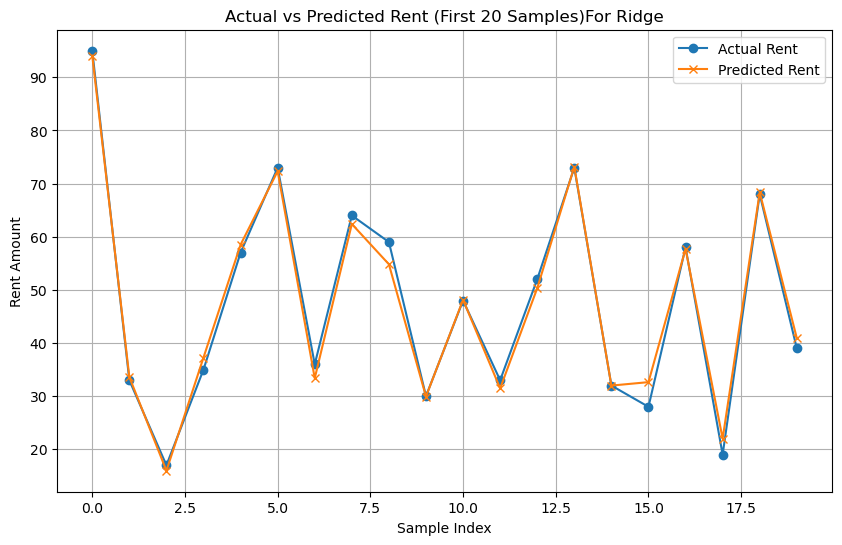

 20%|██        | 3/15 [00:01<00:04,  2.85it/s]

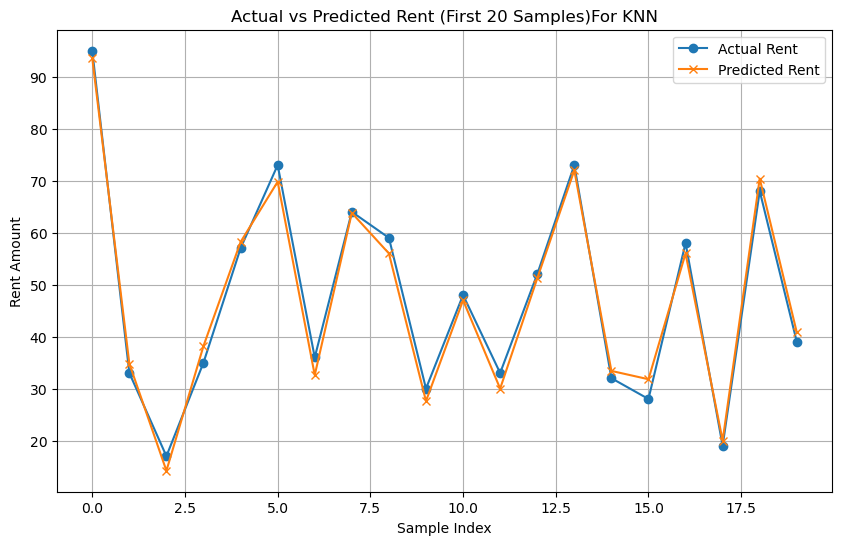

 27%|██▋       | 4/15 [00:01<00:04,  2.53it/s]

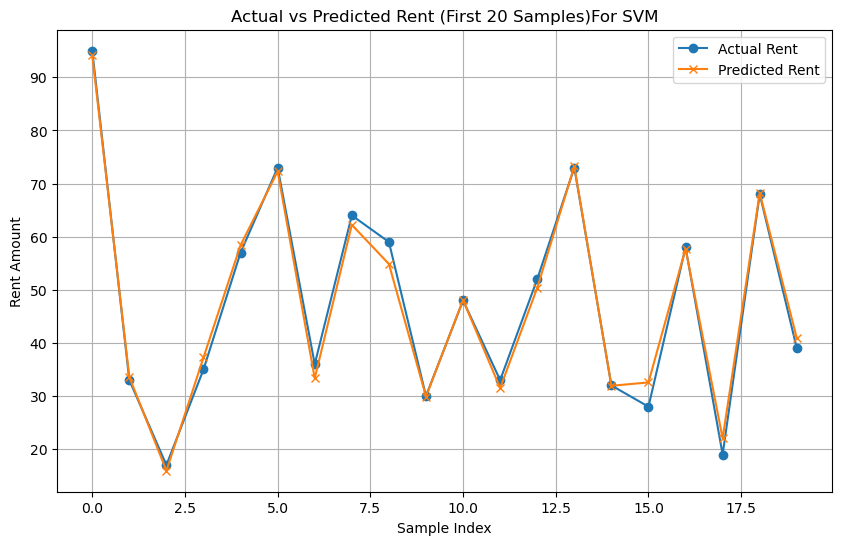

 33%|███▎      | 5/15 [17:36<1:03:25, 380.60s/it]

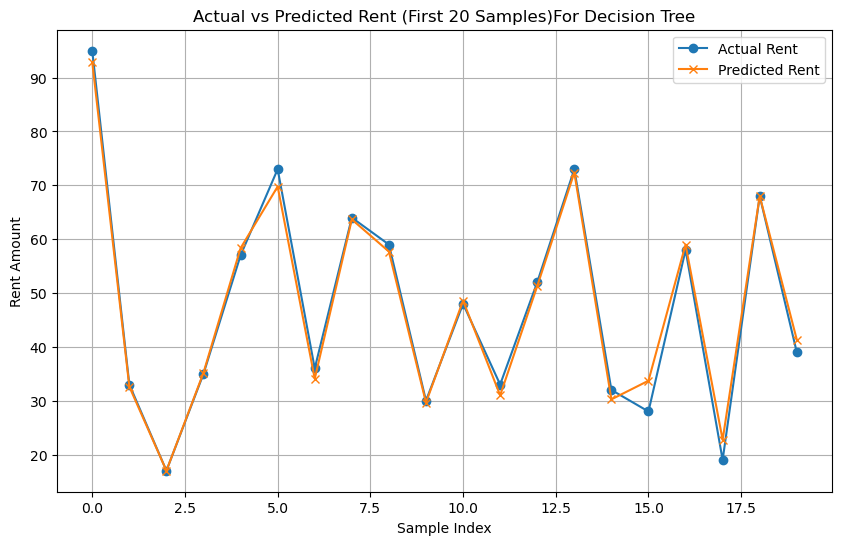

 40%|████      | 6/15 [17:36<37:41, 251.30s/it]  

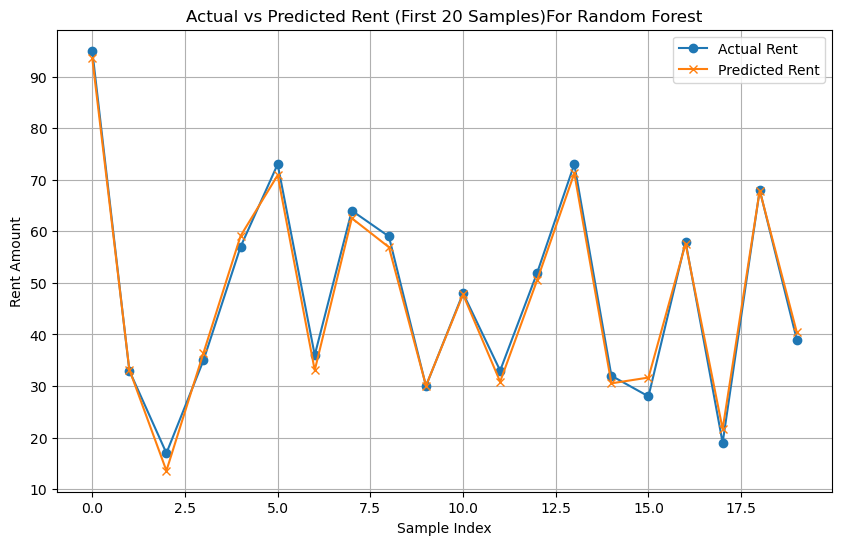

 47%|████▋     | 7/15 [17:37<22:35, 169.49s/it]

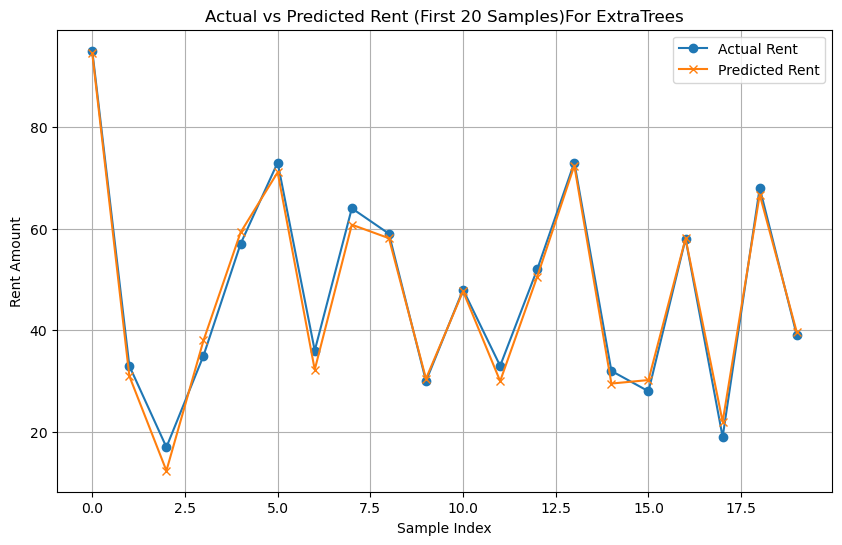

 53%|█████▎    | 8/15 [17:39<13:32, 116.13s/it]

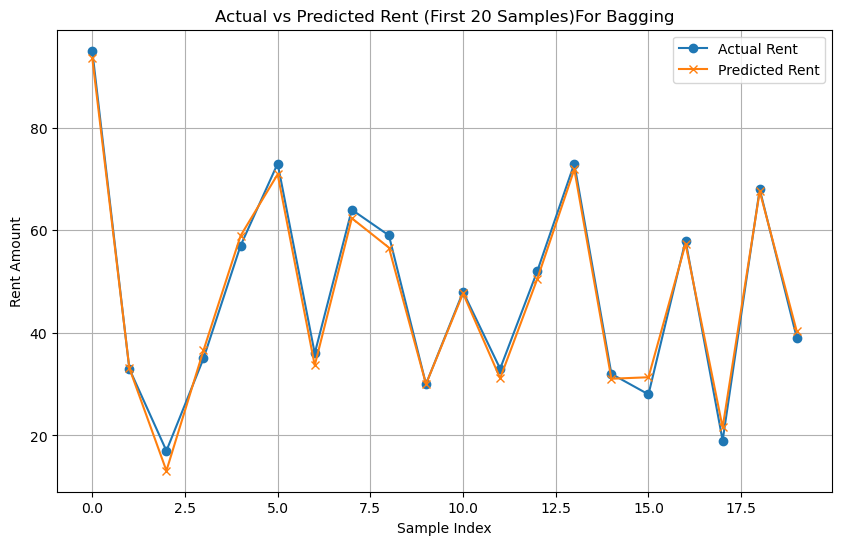

 60%|██████    | 9/15 [17:40<08:00, 80.16s/it] 

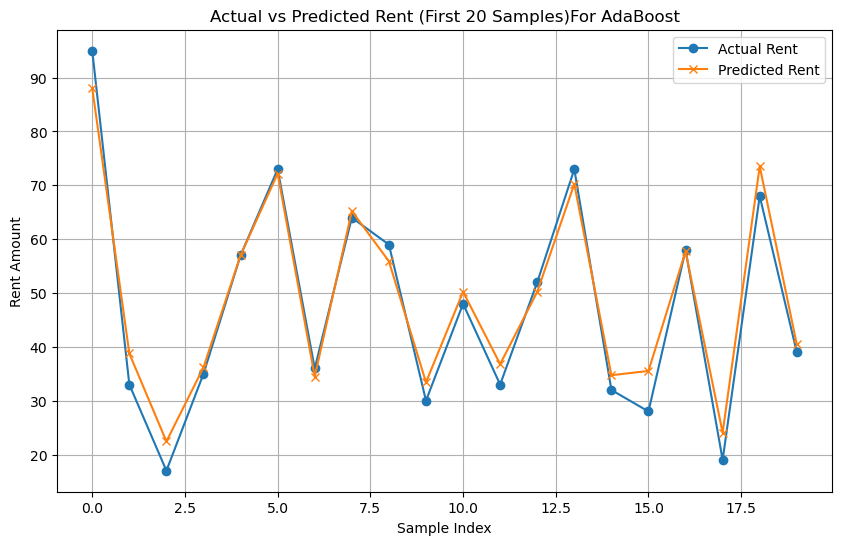

 67%|██████▋   | 10/15 [17:40<04:37, 55.53s/it]

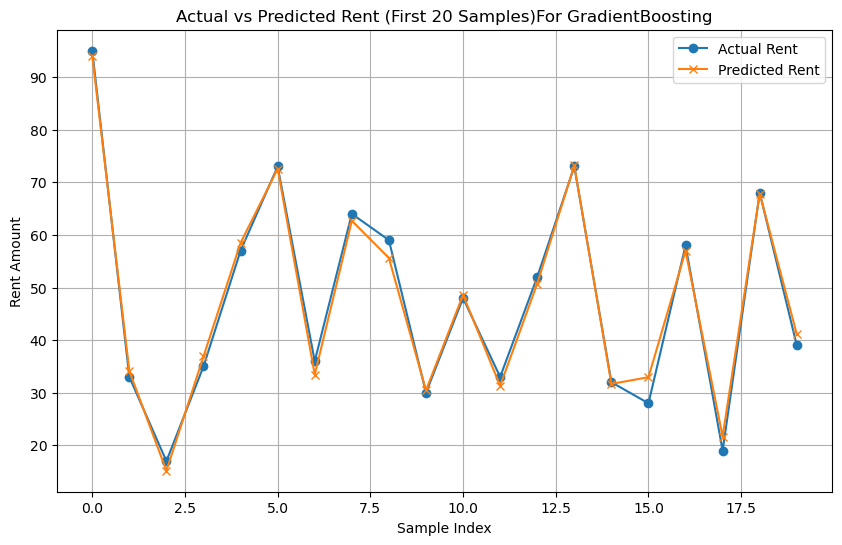

 73%|███████▎  | 11/15 [17:41<02:35, 38.76s/it]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, a

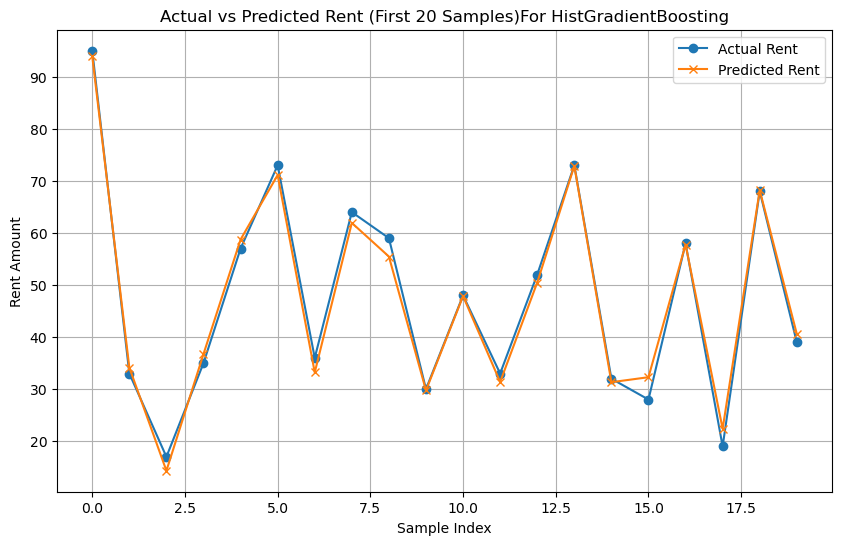

 80%|████████  | 12/15 [17:43<01:22, 27.56s/it]

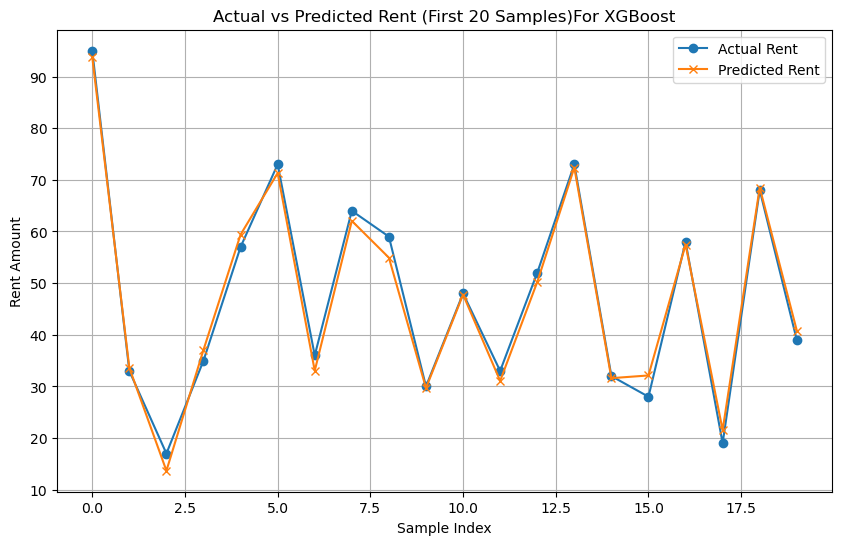

 87%|████████▋ | 13/15 [17:45<00:39, 19.65s/it]

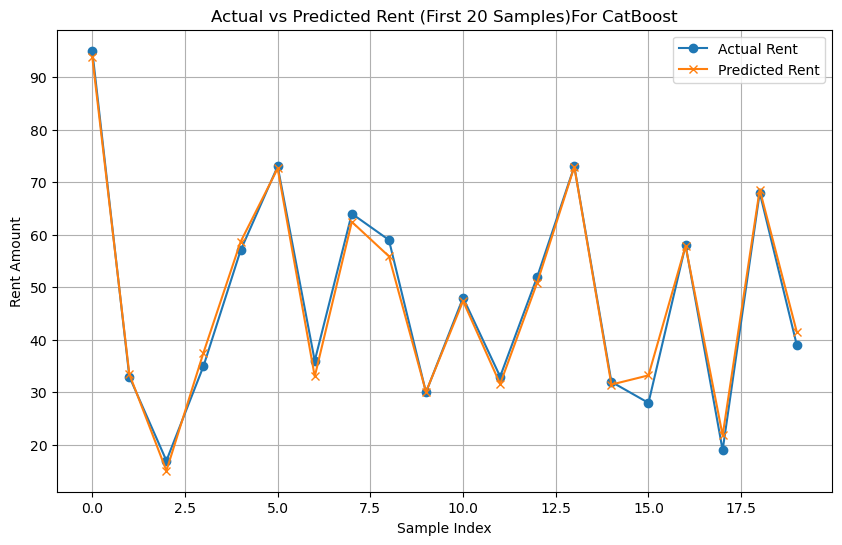

 93%|█████████▎| 14/15 [17:45<00:13, 13.98s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000566 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 99
[LightGBM] [Info] Number of data points in the train set: 7830, number of used features: 5
[LightGBM] [Info] Start training from score 55.132950


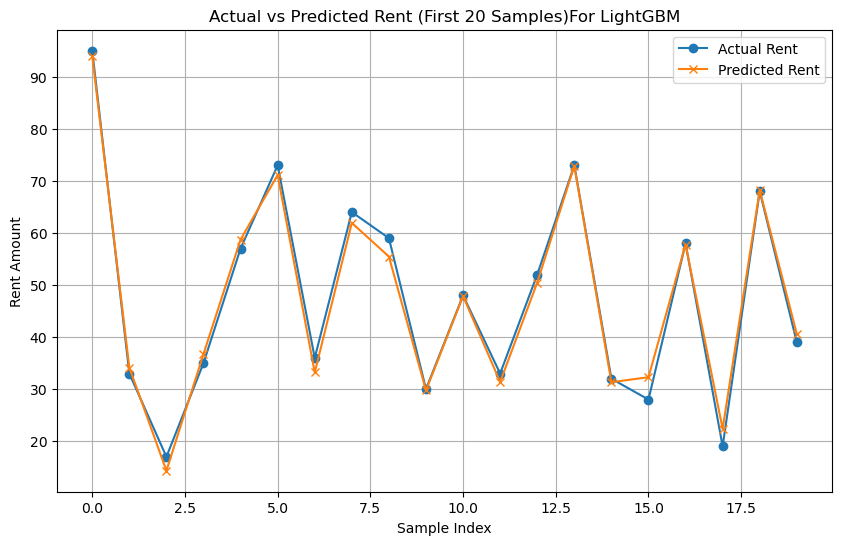

100%|██████████| 15/15 [17:46<00:00, 71.11s/it]


In [37]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [38]:
errors = pd.DataFrame(errors)
errors

,Linear Regression,Lasso,Ridge,KNN,SVM,Decision Tree,Random Forest,ExtraTrees,Bagging,AdaBoost,GradientBoosting,HistGradientBoosting,XGBoost,CatBoost,LightGBM
MAE Train,1.636600,1.772677,1.636603,1.573206,1.635999,1.367070,1.275377,0.118745,1.273864,2.958666,1.624205,1.514289,1.434976,1.630478,1.514289
MAE Test,1.651994,1.755601,1.651987,2.018590,1.654859,2.020486,1.768457,1.965850,1.768000,2.950437,1.701850,1.708147,1.719397,1.682761,1.708028
MSE Train,4.261701,4.968692,4.261701,3.992342,4.265129,3.105705,2.580287,0.215001,2.578223,13.798510,4.179823,3.636766,3.292882,4.218577,3.636766
MSE Test,4.312114,4.853801,4.312069,6.420470,4.323883,6.607537,5.016438,6.427523,5.017517,13.739463,4.578000,4.587631,4.714896,4.512552,4.586315
RMSE Train,2.064389,2.229056,2.064389,1.998085,2.065219,1.762301,1.606327,0.463682,1.605684,3.714635,2.044462,1.907031,1.814630,2.053918,1.907031
RMSE Test,2.076563,2.203134,2.076552,2.533865,2.079395,2.570513,2.239741,2.535256,2.239981,3.706678,2.139626,2.141876,2.171381,2.124277,2.141568
R2 Train,0.988464,0.986551,0.988464,0.989194,0.988455,0.991593,0.993016,0.999418,0.993021,0.962650,0.988686,0.990156,0.991087,0.988581,0.990156
R2 Test,0.988112,0.986619,0.988112,0.982300,0.988080,0.981784,0.986171,0.982281,0.986168,0.962123,0.987379,0.987353,0.987002,0.987560,0.987356
